**🔊 Introduction: Speaker Diarization & Transcription Pipeline:**


This notebook demonstrates a complete pipeline for automatic speech recognition (ASR) and speaker diarization using OpenAI Whisper for transcription and Resemblyzer for speaker embeddings. The goal is to process an uploaded audio file, transcribe the spoken content, and identify who spoke when by clustering speaker segments.


**📌 Key Steps in the Pipeline:**


1. **Dependency Installation:** Installs required libraries such as Whisper, Resemblyzer, Librosa, and visualization tools.

2. **Audio Upload:** Allows the user to upload an audio file directly in Colab.

3. **Transcription (Whisper):** Generates word-level timestamps and transcribes the audio into text.

4. **Speaker Embeddings (Resemblyzer):** Extracts speaker features using a sliding window approach.

5. **Similarity & Clustering:** Computes cosine similarity between embeddings and applies spectral clustering to detect distinct speakers.

6. **Speaker Assignment:** Maps each transcribed word to the most likely speaker.

7. **Segment Grouping:** Groups consecutive words into coherent speaker segments.

8. **Visualization:** Provides heatmaps of similarity and a timeline plot showing speaker turns.

9. **Final Transcript:** Outputs a structured transcript with speaker labels, timestamps, and statistics.

10. **Export Results:** Saves outputs in multiple formats (TXT, JSON, SRT) for easy download and use.

Installing dependencies (this may take 2-3 minutes)...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 16.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 3.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.6/78.6 kB 8.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 72.3 MB/s eta 0:00:00

✓ Installation complete!
GPU Available: True
Device: Tesla T4

UPLOAD YOUR AUDIO FILE


Saving test_audio.wav to test_audio.wav
✓ Uploaded: test_audio.wav
  File size: 4703.73 KB

STEP 1: TRANSCRIBING WITH WHISPER

📊 Audio Information:
  Duration: 27.30 seconds
  Sample Rate: 16000 Hz

🔄 Loading Whisper model on cuda...


100%|███████████████████████████████████████| 139M/139M [00:01<00:00, 83.6MiB/s]


🎤 Transcribing audio with word-level timestamps...

✓ Transcription complete!
  Language: en
  Total segments: 7
  Total words: 73

📝 Sample Word Timestamps (first 10 words):
  [0.0s–0.6s]  So,
  [0.7s–0.9s]  Aaron,
  [1.2s–1.3s]  in
  [1.3s–1.4s]  your
  [1.4s–1.8s]  email
  [1.8s–2.0s]  you
  [2.0s–2.2s]  said
  [2.2s–2.4s]  you
  [2.4s–2.6s]  wanted
  [2.6s–2.8s]  to

STEP 2: EXTRACTING SPEAKER EMBEDDINGS (SLIDING WINDOW)

🔄 Loading voice encoder model...
Loaded the voice encoder model on cuda in 0.05 seconds.
✓ Voice encoder loaded

🎯 Creating sliding windows:
  Window size: 2.0s
  Step size: 0.5s
  Processed 10 windows...
  Processed 20 windows...
  Processed 30 windows...
  Processed 40 windows...
  Processed 50 windows...

✓ Extracted 51 window embeddings

📊 Sample Embeddings (first 3 windows):
  Window 1 [0.0s–2.0s]:
    Embedding vector (first 5 dims): [0.1173476  0.         0.10008721 0.         0.        ]
    Embedding norm: 1.0000
  Window 2 [0.5s–2.5s]:
    Embedding vect

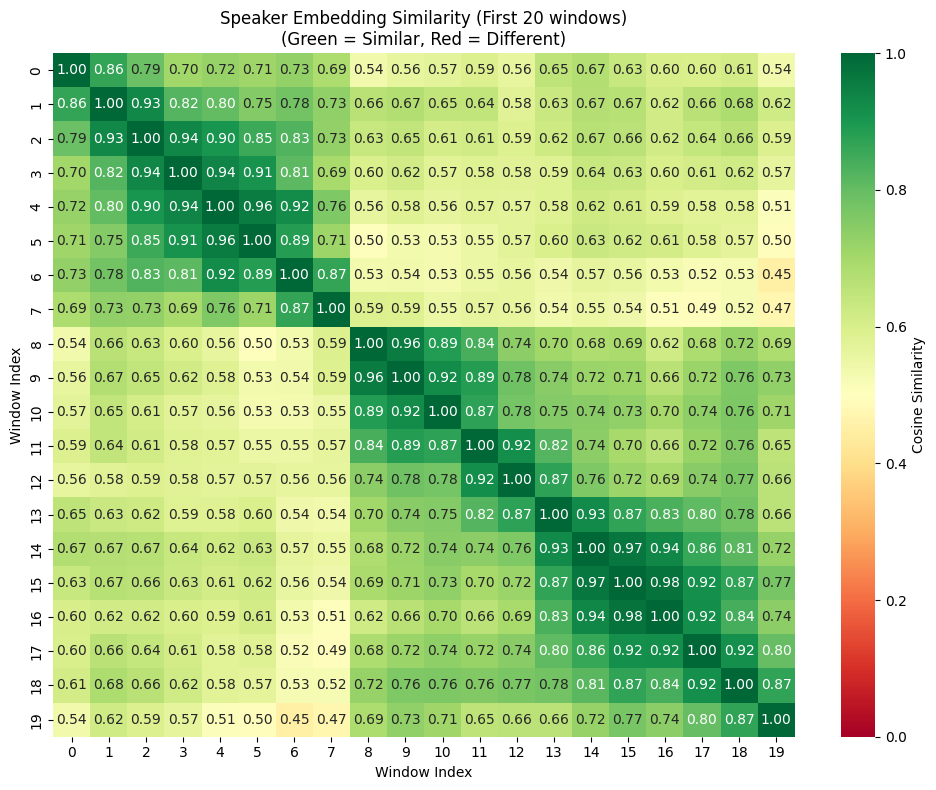


STEP 3: CLUSTERING WINDOWS TO IDENTIFY SPEAKERS

How many speakers? (press Enter for auto-detect): 

🔍 Auto-detecting number of speakers...
  Detected 2 speakers

🔄 Clustering 51 windows into 2 speakers...
✓ Clustering complete

📋 Sample Window-to-Speaker Assignments (first 10 windows):
  Window 1 [0.0s–2.0s] → Cluster 1 (SPEAKER_01)
  Window 2 [0.5s–2.5s] → Cluster 1 (SPEAKER_01)
  Window 3 [1.0s–3.0s] → Cluster 1 (SPEAKER_01)
  Window 4 [1.5s–3.5s] → Cluster 1 (SPEAKER_01)
  Window 5 [2.0s–4.0s] → Cluster 1 (SPEAKER_01)
  Window 6 [2.5s–4.5s] → Cluster 1 (SPEAKER_01)
  Window 7 [3.0s–5.0s] → Cluster 1 (SPEAKER_01)
  Window 8 [3.5s–5.5s] → Cluster 1 (SPEAKER_01)
  Window 9 [4.0s–6.0s] → Cluster 0 (SPEAKER_00)
  Window 10 [4.5s–6.5s] → Cluster 0 (SPEAKER_00)

👥 Speaker Distribution:
  SPEAKER_00: 36 windows (70.6%)
  SPEAKER_01: 15 windows (29.4%)

STEP 4: ASSIGNING SPEAKERS TO WORDS

🔄 Mapping 73 words to speaker labels...
✓ Speaker assignment complete

📋 Sample Word-to-Speaker Assig

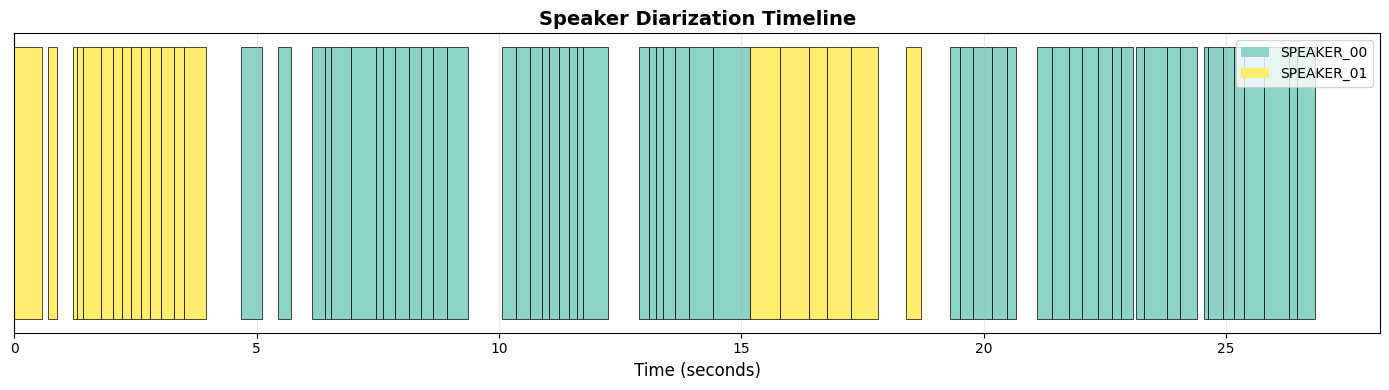


FINAL TRANSCRIPTION WITH SPEAKERS


[SPEAKER_01]
[0.0s] So,
[0.7s] Aaron,
[1.2s] in
[1.3s] your
[1.4s] email
[1.8s] you
[2.0s] said
[2.2s] you
[2.4s] wanted
[2.6s] to
[2.8s] talk
[3.0s] about
[3.3s] the
[3.5s] exam.

[SPEAKER_00]
[4.7s] Yeah,
[5.4s] um,
[6.1s] I've
[6.4s] just
[6.5s] never
[6.9s] taken
[7.5s] a
[7.6s] class
[7.9s] with
[8.1s] so
[8.4s] many
[8.6s] different
[8.9s] readings.
[10.1s] I've
[10.4s] managed
[10.6s] to
[10.9s] keep
[11.0s] up
[11.2s] with
[11.4s] all
[11.6s] the
[11.7s] assignments,
[12.9s] but
[13.1s] I'm
[13.2s] not
[13.4s] sure
[13.6s] how
[13.9s] to...
[14.4s] How

[SPEAKER_01]
[15.2s] to...
[15.8s] How
[16.4s] to
[16.8s] review
[17.3s] everything?
[18.4s] Yeah,

[SPEAKER_00]
[19.3s] and
[19.5s] other
[19.8s] classes
[20.2s] I've
[20.5s] had.
[21.1s] There's
[21.4s] usually
[21.8s] just
[22.0s] one
[22.4s] book
[22.7s] to
[22.8s] review,
[23.1s] not
[23.3s] three
[23.8s] different
[24.1s] books,
[24.6s] plus
[24.6s] all
[24.9s] those
[25.2s] other
[25.4

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Downloaded: transcript_with_speakers.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Downloaded: transcript_detailed.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Downloaded: transcript.srt

✅ ALL DONE!

Processed 73 segments
Identified 2 unique speakers

Files downloaded:
  • transcript_with_speakers.txt
  • transcript_detailed.json
  • transcript.srt


In [ ]:
print("Installing dependencies (this may take 2-3 minutes)...")

!pip install -q openai-whisper
!pip install -q resemblyzer
!pip install -q scikit-learn
!pip install -q librosa
!pip install -q pydub
!pip install -q matplotlib
!pip install -q seaborn

import whisper
import torch
import numpy as np
from resemblyzer import VoiceEncoder, preprocess_wav
from sklearn.cluster import SpectralClustering
from scipy.spatial.distance import cosine, cdist
import librosa
import warnings
import json
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

print(f"\n✓ Installation complete!")
print(f"GPU Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")

# ============================================
# CONFIGURATION
# ============================================
WINDOW_SIZE = 2.0  # seconds - sliding window for speaker embedding
WINDOW_STEP = 0.5  # seconds - step size for sliding window
MIN_SEGMENT_LENGTH = 0.5  # minimum segment length in seconds

# ============================================
# STEP 2: UPLOAD AUDIO FILE
# ============================================
from google.colab import files

print("\n" + "="*60)
print("UPLOAD YOUR AUDIO FILE")
print("="*60)
uploaded = files.upload()

if not uploaded:
    raise Exception("No file uploaded!")

audio_file = list(uploaded.keys())[0]
print(f"✓ Uploaded: {audio_file}")
print(f"  File size: {len(uploaded[audio_file]) / 1024:.2f} KB")

# ============================================
# STEP 3: TRANSCRIBE WITH WHISPER
# ============================================
print("\n" + "="*60)
print("STEP 1: TRANSCRIBING WITH WHISPER")
print("="*60)

audio_data_preview, sr_preview = librosa.load(audio_file, sr=16000)
duration = len(audio_data_preview) / sr_preview
print(f"\n📊 Audio Information:")
print(f"  Duration: {duration:.2f} seconds")
print(f"  Sample Rate: {sr_preview} Hz")

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"\n🔄 Loading Whisper model on {device}...")
model = whisper.load_model("base", device=device)

print("🎤 Transcribing audio with word-level timestamps...")
result = model.transcribe(audio_file, word_timestamps=True)

print(f"\n✓ Transcription complete!")
print(f"  Language: {result['language']}")
print(f"  Total segments: {len(result['segments'])}")

# Extract all words with timestamps
all_words = []
for seg in result['segments']:
    if 'words' in seg:
        for word in seg['words']:
            all_words.append(word)

print(f"  Total words: {len(all_words)}")

# Show sample word timestamps
print(f"\n📝 Sample Word Timestamps (first 10 words):")
for i, word in enumerate(all_words[:10]):
    print(f"  [{word['start']:.1f}s–{word['end']:.1f}s] {word['word']}")

# ============================================
# STEP 4: SLIDING WINDOW SPEAKER EMBEDDINGS
# ============================================
print("\n" + "="*60)
print("STEP 2: EXTRACTING SPEAKER EMBEDDINGS (SLIDING WINDOW)")
print("="*60)

audio_data, sr = librosa.load(audio_file, sr=16000)
print(f"\n🔄 Loading voice encoder model...")
encoder = VoiceEncoder()
print(f"✓ Voice encoder loaded")

# Create sliding windows across the entire audio
windows = []
embeddings = []

print(f"\n🎯 Creating sliding windows:")
print(f"  Window size: {WINDOW_SIZE}s")
print(f"  Step size: {WINDOW_STEP}s")

current_time = 0
window_count = 0

while current_time + WINDOW_SIZE <= duration:
    start_time = current_time
    end_time = current_time + WINDOW_SIZE

    start_sample = int(start_time * sr)
    end_sample = int(end_time * sr)
    audio_chunk = audio_data[start_sample:end_sample]

    try:
        processed = preprocess_wav(audio_chunk, sr)
        emb = encoder.embed_utterance(processed)
        embeddings.append(emb)
        windows.append({'start': start_time, 'end': end_time, 'center': (start_time + end_time) / 2})
        window_count += 1

        if window_count % 10 == 0:
            print(f"  Processed {window_count} windows...")
    except:
        pass

    current_time += WINDOW_STEP

print(f"\n✓ Extracted {len(embeddings)} window embeddings")

# Show sample embeddings
print(f"\n📊 Sample Embeddings (first 3 windows):")
for i in range(min(3, len(windows))):
    print(f"  Window {i+1} [{windows[i]['start']:.1f}s–{windows[i]['end']:.1f}s]:")
    print(f"    Embedding vector (first 5 dims): {embeddings[i][:5]}")
    print(f"    Embedding norm: {np.linalg.norm(embeddings[i]):.4f}")

# ============================================
# VISUALIZE EMBEDDINGS
# ============================================
print("\n" + "="*60)
print("VISUALIZATION: EMBEDDING SIMILARITY")
print("="*60)

X = np.array(embeddings)

# Compute similarity matrix
similarity_matrix = 1 - cdist(X, X, metric='cosine')
print(f"\n📊 Similarity matrix computed: {similarity_matrix.shape}")

# Show sample similarity values
print(f"\n📊 Sample Similarity Matrix (first 5x5):")
sample_size = min(5, len(X))
print("     ", end="")
for i in range(sample_size):
    print(f"W{i+1:2d}   ", end="")
print()
for i in range(sample_size):
    print(f"W{i+1:2d} ", end="")
    for j in range(sample_size):
        print(f"{similarity_matrix[i,j]:.2f}  ", end="")
    print()

print(f"\n💡 Interpretation:")
print(f"  High values (>0.80) = likely same speaker")
print(f"  Low values (<0.70) = likely different speakers")

# Show a sample of the similarity matrix (too large to show all)
sample_size = min(20, len(X))
plt.figure(figsize=(10, 8))
sns.heatmap(similarity_matrix[:sample_size, :sample_size],
            annot=True,
            fmt='.2f',
            cmap='RdYlGn',
            vmin=0, vmax=1,
            cbar_kws={'label': 'Cosine Similarity'})
plt.title(f'Speaker Embedding Similarity (First {sample_size} windows)\n(Green = Similar, Red = Different)')
plt.xlabel('Window Index')
plt.ylabel('Window Index')
plt.tight_layout()
plt.show()

# ============================================
# STEP 5: CLUSTER WINDOWS TO IDENTIFY SPEAKERS
# ============================================
print("\n" + "="*60)
print("STEP 3: CLUSTERING WINDOWS TO IDENTIFY SPEAKERS")
print("="*60)

num_speakers_input = input("\nHow many speakers? (press Enter for auto-detect): ").strip()

if num_speakers_input:
    num_speakers = int(num_speakers_input)
    print(f"\n✓ Using user-specified: {num_speakers} speakers")
else:
    print("\n🔍 Auto-detecting number of speakers...")

    # Calculate eigenvalue gap
    from scipy.linalg import eigh
    eigenvalues, _ = eigh(similarity_matrix)
    eigenvalues = np.sort(eigenvalues)[::-1]

    max_speakers = min(8, len(X))
    eigengaps = []
    for i in range(1, min(max_speakers, len(eigenvalues)-1)):
        gap = eigenvalues[i-1] - eigenvalues[i]
        eigengaps.append(gap)

    best_n = np.argmax(eigengaps) + 1
    num_speakers = max(2, min(best_n, max_speakers))
    print(f"  Detected {num_speakers} speakers")

# Cluster windows
print(f"\n🔄 Clustering {len(windows)} windows into {num_speakers} speakers...")
clustering = SpectralClustering(
    n_clusters=num_speakers,
    affinity='precomputed',
    assign_labels='kmeans',
    random_state=42
)
window_labels = clustering.fit_predict(similarity_matrix)

print(f"✓ Clustering complete")

# Show sample window assignments
print(f"\n📋 Sample Window-to-Speaker Assignments (first 10 windows):")
for i in range(min(10, len(windows))):
    print(f"  Window {i+1} [{windows[i]['start']:.1f}s–{windows[i]['end']:.1f}s] → Cluster {window_labels[i]} (SPEAKER_{window_labels[i]:02d})")

print(f"\n👥 Speaker Distribution:")
for i in range(num_speakers):
    count = np.sum(window_labels == i)
    print(f"  SPEAKER_{i:02d}: {count} windows ({count/len(window_labels)*100:.1f}%)")

# ============================================
# STEP 6: ASSIGN SPEAKERS TO WORDS
# ============================================
print("\n" + "="*60)
print("STEP 4: ASSIGNING SPEAKERS TO WORDS")
print("="*60)

print(f"\n🔄 Mapping {len(all_words)} words to speaker labels...")

# For each word, find the closest window and assign its speaker
for word in all_words:
    word_time = (word['start'] + word['end']) / 2

    # Find closest window center
    closest_idx = 0
    min_dist = float('inf')

    for i, window in enumerate(windows):
        dist = abs(window['center'] - word_time)
        if dist < min_dist:
            min_dist = dist
            closest_idx = i

    word['speaker'] = window_labels[closest_idx]

print(f"✓ Speaker assignment complete")

# Show sample word-to-speaker assignments
print(f"\n📋 Sample Word-to-Speaker Assignments (first 15 words):")
for i in range(min(15, len(all_words))):
    word = all_words[i]
    print(f"  {word['word']:15s} → SPEAKER_{word['speaker']:02d}")

# ============================================
# STEP 7: GROUP WORDS INTO SPEAKER SEGMENTS
# ============================================
print("\n" + "="*60)
print("STEP 5: CREATING SPEAKER SEGMENTS")
print("="*60)

print(f"\n🔄 Grouping consecutive words by same speaker...")

# Group consecutive words with same speaker
speaker_segments = []
current_segment = None

for word in all_words:
    speaker = word['speaker']

    if current_segment is None or current_segment['speaker'] != speaker:
        # Start new segment
        if current_segment is not None:
            speaker_segments.append(current_segment)

        current_segment = {
            'speaker': f"SPEAKER_{speaker:02d}",
            'start': word['start'],
            'end': word['end'],
            'words': [word['word']]
        }
    else:
        # Continue current segment
        current_segment['end'] = word['end']
        current_segment['words'].append(word['word'])

# Add last segment
if current_segment is not None:
    speaker_segments.append(current_segment)

print(f"✓ Created {len(speaker_segments)} speaker segments")

# Combine text for each segment
for seg in speaker_segments:
    seg['text'] = ' '.join(seg['words']).strip()

# Show sample segments
print(f"\n📋 Sample Speaker Segments (first 5):")
for i in range(min(5, len(speaker_segments))):
    seg = speaker_segments[i]
    print(f"  [{seg['speaker']}] [{seg['start']:.1f}s–{seg['end']:.1f}s] {seg['text'][:60]}{'...' if len(seg['text']) > 60 else ''}")

# ============================================
# VISUALIZATION: SPEAKER TIMELINE
# ============================================
print("\n" + "="*60)
print("VISUALIZATION: SPEAKER TIMELINE")
print("="*60)

plt.figure(figsize=(14, 4))
colors = plt.cm.Set3(np.linspace(0, 1, num_speakers))

for seg in speaker_segments:
    speaker_id = int(seg['speaker'].split('_')[1])
    plt.barh(0, seg['end']-seg['start'], left=seg['start'],
             height=0.5, color=colors[speaker_id],
             edgecolor='black', linewidth=0.5)

plt.yticks([])
plt.xlabel('Time (seconds)', fontsize=12)
plt.title('Speaker Diarization Timeline', fontsize=14, weight='bold')
plt.grid(True, alpha=0.3, axis='x')

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colors[i], label=f'SPEAKER_{i:02d}')
                   for i in range(num_speakers)]
plt.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

# ============================================
# STEP 8: DISPLAY RESULTS
# ============================================
print("\n" + "="*60)
print("FINAL TRANSCRIPTION WITH SPEAKERS")
print("="*60 + "\n")

transcript_lines = []
current_speaker = None

for seg in speaker_segments:
    speaker = seg['speaker']
    start = seg['start']
    text = seg['text']

    if speaker != current_speaker:
        speaker_line = f"\n[{speaker}]"
        print(speaker_line)
        transcript_lines.append(speaker_line)
        current_speaker = speaker

    line = f"[{start:.1f}s] {text}"
    print(line)
    transcript_lines.append(line)

# ============================================
# STATISTICS
# ============================================
print("\n" + "="*60)
print("STATISTICS")
print("="*60)

for i in range(num_speakers):
    speaker_name = f"SPEAKER_{i:02d}"
    speaker_segs = [s for s in speaker_segments if s['speaker'] == speaker_name]
    total_time = sum([s['end'] - s['start'] for s in speaker_segs])
    total_words = sum([len(s['words']) for s in speaker_segs])

    print(f"\n{speaker_name}:")
    print(f"  Segments: {len(speaker_segs)}")
    print(f"  Total speaking time: {total_time:.1f}s ({total_time/duration*100:.1f}%)")
    print(f"  Total words: {total_words}")

# ============================================
# STEP 9: SAVE AND DOWNLOAD
# ============================================
print("\n" + "="*60)
print("SAVING RESULTS")
print("="*60)

# Save as TXT
output_file = "transcript_with_speakers.txt"
with open(output_file, "w", encoding="utf-8") as f:
    f.write("\n".join(transcript_lines))
files.download(output_file)
print(f"✓ Downloaded: {output_file}")

# Save as JSON
json_output = "transcript_detailed.json"
with open(json_output, "w", encoding="utf-8") as f:
    json.dump({
        'language': result['language'],
        'segments': speaker_segments,
        'num_speakers': num_speakers
    }, f, indent=2, ensure_ascii=False)
files.download(json_output)
print(f"✓ Downloaded: {json_output}")

# Save as SRT
srt_output = "transcript.srt"
with open(srt_output, "w", encoding="utf-8") as f:
    for i, seg in enumerate(speaker_segments, 1):
        speaker = seg['speaker']
        start = seg['start']
        end = seg['end']
        text = seg['text']

        start_time = f"{int(start//3600):02d}:{int((start%3600)//60):02d}:{int(start%60):02d},{int((start%1)*1000):03d}"
        end_time = f"{int(end//3600):02d}:{int((end%3600)//60):02d}:{int(end%60):02d},{int((end%1)*1000):03d}"

        f.write(f"{i}\n{start_time} --> {end_time}\n[{speaker}] {text}\n\n")
files.download(srt_output)
print(f"✓ Downloaded: {srt_output}")

print("\n" + "="*60)
print("✅ ALL DONE!")
print("="*60)
print(f"\nProcessed {len(speaker_segments)} segments")
print(f"Identified {num_speakers} unique speakers")
print("\nFiles downloaded:")
print("  • transcript_with_speakers.txt")
print("  • transcript_detailed.json")
print("  • transcript.srt")